# Kerr effect and self-focusing

The third-order susceptibility $\chi^{(3)}$ exists in every material,
glass and air included. Its most important consequence is the **optical
Kerr effect**: the index grows with the intensity,

$$n = n_0 + n_2I,$$

with $n_2$ of a few 10⁻²⁰ m²/W in glasses and crystals. That is tiny,
but a focused laser pulse reaches TW/cm², and the index change acts on
the beam itself. Across the beam profile it makes a lens (**self-focusing**,
the **Kerr lens**), along a pulse it makes a time dependent phase
(**self-phase modulation**, SPM). Self-focusing destroys high-power
optics, SPM broadens spectra, and the Kerr lens is the fast shutter of
femtosecond lasers.

This notebook uses the `nonlinear` module and the split-step beam
propagation of the `splitstep` module:

1. $n_2$ and the critical power of common materials,
2. the Kerr lens of a Gaussian beam,
3. whole-beam self-focusing and collapse: simulation against Marburger's
   formula,
4. small-scale self-focusing in high-power amplifiers (Bespalov–Talanov),
5. self-phase modulation of a femtosecond pulse in a thin plate,
6. Kerr-lens mode-locking: the effective saturable loss of a Ti:sapphire
   resonator in the master equation of notebook 143 (Q-switching and mode-locking).

SPM over kilometres of fibre, where it meets dispersion and makes
solitons, is the subject of notebook 121 (SPM and solitons in fibres);
second-order effects are in notebooks 145 (second harmonic generation and phase matching) and 146 (parametric amplification and OPOs).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from pyoptics import abcd
from pyoptics import lasers as LS
from pyoptics import nonlinear as NL
from pyoptics import splitstep as SS
from pyoptics.ultrafast import fwhm

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. The nonlinear index

For a linearly polarized wave the Kerr coefficient is
$n_2 = 3\chi^{(3)}/(4n_0^2\varepsilon_0c)$ (Boyd's convention). In solids
and liquids at near-infrared wavelengths it comes mostly from the
electronic response, which is instantaneous on femtosecond time scales;
in CS₂ and other molecular liquids the reorientation of molecules adds a
slower, much larger part. A beam of intensity $I$ acquires the nonlinear
phase $\phi = k_0n_2IL$. A useful scale is the **critical power** of
self-focusing, $P_{cr} = 3.77\lambda^2/(8\pi n_0n_2)$, which does not
depend on the beam size (section 3).

In [2]:
lam = 800E-9
print("material        n2 (m²/W)   P_cr at 800 nm   I for 1 rad in 1 cm")
for mat, n0 in (("air", 1.0003), ("fused silica", 1.453), ("BK7", 1.511), ("water", 1.33),
                ("sapphire", 1.76), ("YAG", 1.82), ("CS2", 1.63)):
    n2 = NL.N2[mat]
    I1 = 1/(2*np.pi/lam*n2*1E-2)
    print("{:14s} {:10.2e}   {:10.3g} MW   {:10.3g} GW/cm²".format(mat, n2, NL.critical_power(lam, n0, n2)/1E6, I1/1E13))

material        n2 (m²/W)   P_cr at 800 nm   I for 1 rad in 1 cm
air              3.00e-23      3.2e+03 MW     4.24e+04 GW/cm²
fused silica     2.70e-20         2.45 MW         47.2 GW/cm²
BK7              3.40e-20         1.87 MW         37.4 GW/cm²
water            4.10e-20         1.76 MW         31.1 GW/cm²
sapphire         3.00e-20         1.82 MW         42.4 GW/cm²
YAG              6.20e-20        0.851 MW         20.5 GW/cm²
CS2              3.00e-18       0.0196 MW        0.424 GW/cm²


One radian in a centimetre needs about 50 GW/cm² in fused silica: far
above anything a continuous laser can do, but a 100 fs pulse of 1 µJ
focused to 50 µm reaches it. The critical power is 2.5 MW in fused silica
and 3 GW in air at 800 nm.

## 2. The Kerr lens

A Gaussian beam of power $P$ and radius $w$ has the peak intensity
$2P/(\pi w^2)$, and near the axis
$I \approx I_0(1 - 2r^2/w^2)$: the nonlinear phase is a parabola, a thin
lens of focal length

$$f_{\rm Kerr} = \frac{\pi w^4}{8n_2LP}$$

(`NL.kerr_lens_focal()`). It is positive for $n_2 > 0$ and becomes
stronger with the fourth power of the inverse beam size. Away from the
axis the Gaussian phase falls below the parabola: the Kerr lens has
spherical aberration, which is why a self-focused beam does not stay
Gaussian.

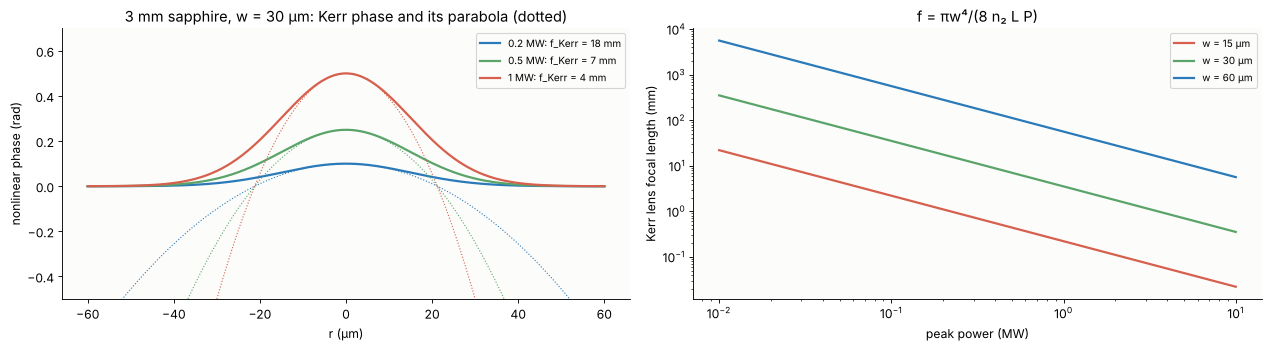

In [3]:
w = 30E-6
n2_sa, L_sa = NL.N2["sapphire"], 3E-3
r = np.linspace(-2*w, 2*w, 401)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ax = axes[0]
for P, c in ((0.2E6, BLUE), (0.5E6, GREEN), (1E6, RED)):
    I = 2*P/(np.pi*w**2)*np.exp(-2*r**2/w**2)
    phi = NL.kerr_phase(I, n2_sa, L_sa, lam)
    f_k = NL.kerr_lens_focal(P, w, n2_sa, L_sa)
    ax.plot(r*1E6, phi, color=c, lw=2, label=f"{P/1E6:g} MW: f_Kerr = {f_k*1E3:.0f} mm")
    ax.plot(r*1E6, phi[200] - 2*np.pi/lam*r**2/(2*f_k), color=c, lw=1, ls=":")
ax.set_ylim(-0.5, None)
ax.set_xlabel("r (µm)"); ax.set_ylabel("nonlinear phase (rad)")
ax.set_title("3 mm sapphire, w = 30 µm: Kerr phase and its parabola (dotted)"); ax.legend(fontsize=9)
ax = axes[1]
Ps = np.logspace(4, 7, 100)
for wk, c in ((15E-6, RED), (30E-6, GREEN), (60E-6, BLUE)):
    ax.loglog(Ps/1E6, NL.kerr_lens_focal(Ps, wk, n2_sa, L_sa)*1E3, color=c, lw=2, label=f"w = {wk*1E6:.0f} µm")
ax.set_xlabel("peak power (MW)"); ax.set_ylabel("Kerr lens focal length (mm)")
ax.set_title("f = πw⁴/(8 n₂ L P)"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In 3 mm of sapphire a 30 µm beam of 1 MW (a 10 fs pulse of 10 nJ, as in a
Ti:sapphire laser) makes a lens of 3.5 mm focal length, much stronger
than the 50 mm of the curved mirrors around the crystal; the 53 µm mode
of the resonator in section 6 sees 34 mm, still comparable with them.

## 3. Self-focusing and collapse

In a long medium the Kerr lens competes with diffraction. The paraxial
wave equation with the Kerr term,

$$\frac{\partial E}{\partial z} = \frac{i}{2k}\nabla_\perp^2E + ik_0n_2|E|^2E,$$

is solved here with the symmetric split-step method of `SS.beam_propagate()`
on a 384 × 384 grid, with the step chosen for 0.08 rad of nonlinear phase
per step. Since both terms scale in the same way with the beam size, the
balance depends only on the power: below $P_{cr}$ diffraction wins, above
it the beam focuses ever more strongly and **collapses** to a point at a
finite distance, which Marburger fitted as

$$z_c = \frac{0.367\,z_R}{\sqrt{(\sqrt{P/P_{cr}} - 0.852)^2 - 0.0219}}$$

for a collimated Gaussian beam with the Rayleigh length $z_R$
(`NL.self_focusing_distance()`). The simulation stops when the peak
intensity has grown 60 times.

fused silica, 800 nm: P_cr = 2.45 MW, w0 = 100 µm, z_R = 57.1 mm


P = 0.50 P_cr: collapse at    nan mm, Marburger    nan mm
P = 0.95 P_cr: collapse at    nan mm, Marburger    nan mm
P = 1.50 P_cr: collapse at   53.6 mm, Marburger   61.2 mm
P = 3.00 P_cr: collapse at   22.4 mm, Marburger   24.1 mm
P = 6.00 P_cr: collapse at   12.6 mm, Marburger   13.2 mm


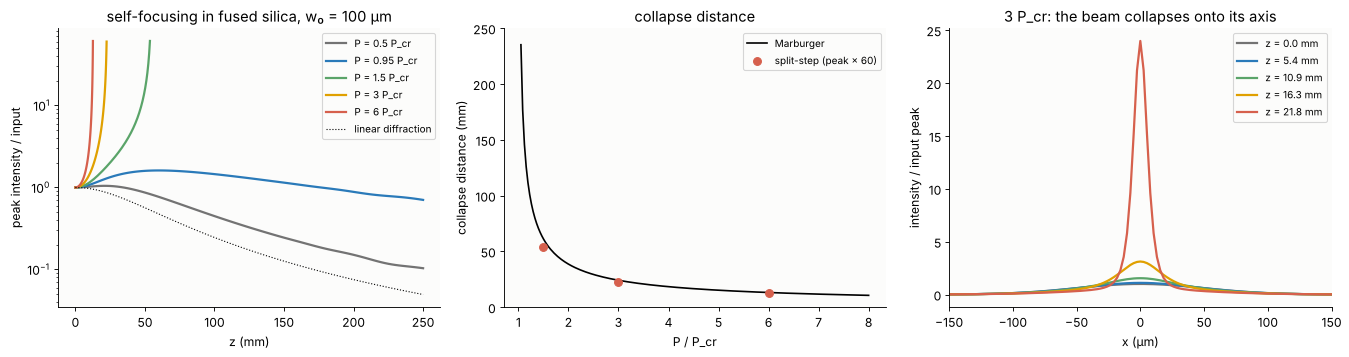

In [4]:
n0_fs, n2_fs, w0 = 1.453, NL.N2["fused silica"], 100E-6
P_cr = NL.critical_power(lam, n0_fs, n2_fs)
x = np.linspace(-0.5E-3, 0.5E-3, 384, endpoint=False)
X, Y = np.meshgrid(x, x)
z_R = np.pi*n0_fs*w0**2/lam
print("fused silica, 800 nm: P_cr = {:.2f} MW, w0 = {:.0f} µm, z_R = {:.1f} mm".format(P_cr/1E6, w0*1E6, z_R*1E3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ratios = (0.5, 0.95, 1.5, 3.0, 6.0)
z_col = {}
for p, c in zip(ratios, (GREY, BLUE, GREEN, ORANGE, RED)):
    I0 = 2*p*P_cr/(np.pi*w0**2)
    E0 = np.sqrt(I0)*np.exp(-(X**2 + Y**2)/w0**2)
    E, zz, peak = SS.beam_propagate((x, x), E0, 0.25, lam, n0_fs, n2_fs, max_phase=0.08, stop_intensity=60*I0)
    axes[0].semilogy(zz*1E3, peak/I0, color=c, lw=2, label=f"P = {p:g} P_cr")
    z_col[p] = zz[-1] if peak[-1] > 59*I0 else np.nan
axes[0].semilogy(np.linspace(0, 250, 100), 1/(1 + (np.linspace(0, 250, 100)/(z_R*1E3))**2), color="k", lw=1, ls=":",
                 label="linear diffraction")
axes[0].set_xlabel("z (mm)"); axes[0].set_ylabel("peak intensity / input")
axes[0].set_title("self-focusing in fused silica, w₀ = 100 µm"); axes[0].legend(fontsize=9)
ax = axes[1]
pp = np.linspace(1.05, 8, 200)
ax.plot(pp, NL.self_focusing_distance(pp*P_cr, P_cr, w0, lam, n0_fs)*1E3, color="k", lw=1.5, label="Marburger")
ax.set_ylim(0, 250)
ax.plot(list(z_col), np.array(list(z_col.values()))*1E3, "o", color=RED, ms=7, label="split-step (peak × 60)")
ax.set_xlabel("P / P_cr"); ax.set_ylabel("collapse distance (mm)"); ax.legend(fontsize=9)
ax.set_title("collapse distance")
for p in ratios:
    print("P = {:4.2f} P_cr: collapse at {:6.1f} mm, Marburger {:6.1f} mm".format(
        p, z_col[p]*1E3, NL.self_focusing_distance(p*P_cr, P_cr, w0, lam, n0_fs)*1E3))
# profiles on the way to collapse at 3 P_cr
ax = axes[2]
I0 = 2*3.0*P_cr/(np.pi*w0**2)
E0 = np.sqrt(I0)*np.exp(-(X**2 + Y**2)/w0**2)
zc = z_col[3.0]
E, zs, peaks, hist = SS.beam_propagate((x, x), E0, 0.97*zc, lam, n0_fs, n2_fs, max_phase=0.08, n_save=5)
for k, c in zip(range(len(zs)), (GREY, BLUE, GREEN, ORANGE, RED)):
    I_line = np.abs(hist[k][len(x)//2])**2
    ax.plot(x*1E6, I_line/I0, color=c, lw=2, label=f"z = {zs[k]*1E3:.1f} mm")
ax.set_xlim(-150, 150); ax.set_xlabel("x (µm)"); ax.set_ylabel("intensity / input peak")
ax.set_title("3 P_cr: the beam collapses onto its axis"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

At half the critical power the beam spreads a little more slowly than in
linear diffraction; at 0.95 $P_{cr}$ it first contracts, then spreads.
Above $P_{cr}$ it collapses: at 6 $P_{cr}$ after 12.6 mm (Marburger:
13.2 mm), at 3 $P_{cr}$ after 22.4 mm (24.1 mm), at 1.5 $P_{cr}$ after
54 mm (61 mm), within 5 to 12 % of the fit, which itself is good to a
few percent and refers to the singular collapse, not to a 60-fold peak.
The profile narrows onto the axis and develops wings: only the central
part, which carries about $P_{cr}$, collapses (the Townes profile). In a
real material the collapse is stopped by multiphoton absorption and the
plasma it makes (`mpa=` in `SS.beam_propagate()`), which leaves a
**filament** and damage tracks in glass, or a light string in air.

## 4. Small-scale self-focusing

A high-power laser amplifier carries many times $P_{cr}$ in a wide,
flat beam. It does not collapse as a whole, but every small ripple of
the intensity is a local Kerr lens that focuses itself. Bespalov and
Talanov showed that a plane wave of intensity $I$ amplifies transverse
modulations with the wave number $K$ exponentially; the fastest grows at

$$K_m = \sqrt{2kk_0n_2I},$$

with a gain $e^B$ in amplitude, where $B = k_0n_2\int I\,dz$ is the
**B-integral**. The example is a 5 GW/cm² beam at 1053 nm in Nd:glass with
10⁻⁴ of random noise; the dashed curves are the linearized theory for
noise in both quadratures.

most unstable ripple: period 496 µm (1.4 mrad); B = 1 per 11.2 cm


B = 2: largest growth    7.4 at K =  15.1/mm (theory    5.7 at  14.8/mm, e^B/sqrt(2) =    5.2)


B = 4: largest growth   50.7 at K =  14.1/mm (theory   40.0 at  13.5/mm, e^B/sqrt(2) =   38.6)


B = 6: largest growth  354.1 at K =  14.1/mm (theory  291.8 at  13.2/mm, e^B/sqrt(2) =  285.3)


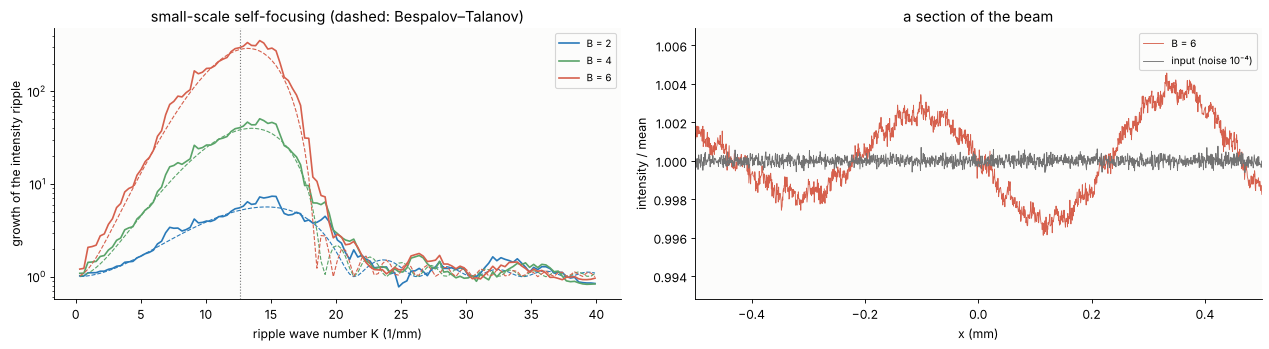

In [5]:
lam_g, n0_g, n2_g = 1053E-9, 1.5, 3.0E-20             # Nd:glass amplifier
I_g = 5E13                                            # 5 GW/cm²
k0_g = 2*np.pi/lam_g
k_g = n0_g*k0_g
xg = np.linspace(-10E-3, 10E-3, 2**15, endpoint=False)
rng = np.random.default_rng(0)
E0 = np.sqrt(I_g)*(1 + 1E-4*(rng.standard_normal(len(xg)) + 1j*rng.standard_normal(len(xg))))
K = 2*np.pi*np.fft.fftfreq(len(xg), xg[1] - xg[0])
pos = (K > 0) & (K < 4E4)
S0 = np.abs(np.fft.fft(np.abs(E0)**2/I_g - 1))
K_m = np.sqrt(2*k_g*k0_g*n2_g*I_g)
print("most unstable ripple: period {:.0f} µm ({:.1f} mrad); B = 1 per {:.1f} cm".format(
    2*np.pi/K_m*1E6, K_m/k_g*1E3, 1/(k0_g*n2_g*I_g)*100))


def ripple_gain(Kv, B):
    """rms gain of the intensity ripple for noise in both quadratures (Bespalov–Talanov)"""
    L = B/(k0_g*n2_g*I_g)
    out = []
    for kk in Kv:
        a = kk**2/(2*k_g)
        M = expm(np.array([[0.0, a], [-a + 2*k0_g*n2_g*I_g, 0.0]])*L)
        out.append(np.hypot(M[0, 0], M[0, 1]))
    return np.array(out)


fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for B, c in ((2, BLUE), (4, GREEN), (6, RED)):
    Lb = B/(k0_g*n2_g*I_g)
    E, zz, peak = SS.beam_propagate(xg, E0, Lb, lam_g, n0_g, n2_g, max_phase=0.02)
    S = np.abs(np.fft.fft(np.abs(E)**2/I_g - 1))
    kern = np.ones(9)/9                          # average the noise power over neighbouring K first
    ratio = np.sqrt(np.convolve(S[pos]**2, kern, "same")/np.convolve(S0[pos]**2, kern, "same"))
    axes[0].semilogy(K[pos]/1E3, ratio, color=c, lw=1.5, label=f"B = {B}")
    k_peak = K[pos][np.argmax(ratio)]
    theory = ripple_gain(K[pos], B)
    print("B = {}: largest growth {:6.1f} at K = {:5.1f}/mm (theory {:6.1f} at {:5.1f}/mm, e^B/sqrt(2) = {:6.1f})".format(
        B, ratio.max(), k_peak/1E3, theory.max(), K[pos][np.argmax(theory)]/1E3, np.exp(B)/np.sqrt(2)))
    axes[0].semilogy(K[pos]/1E3, ripple_gain(K[pos], B), color=c, lw=1, ls="--")
    if B == 6:
        axes[1].plot(xg*1E3, np.abs(E)**2/I_g, color=c, lw=0.8, label=f"B = {B}")
axes[0].axvline(K_m/1E3, color=GREY, ls=":", lw=1)
axes[0].set_xlabel("ripple wave number K (1/mm)"); axes[0].set_ylabel("growth of the intensity ripple")
axes[0].set_title("small-scale self-focusing (dashed: Bespalov–Talanov)"); axes[0].legend(fontsize=9)
axes[1].plot(xg*1E3, np.abs(E0)**2/I_g, color=GREY, lw=0.8, label="input (noise 10⁻⁴)")
axes[1].set_xlim(-0.5, 0.5); axes[1].set_xlabel("x (mm)"); axes[1].set_ylabel("intensity / mean")
axes[1].set_title("a section of the beam"); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

The ripples with periods near 0.5 mm grow fastest, 350 times at
$B$ = 6, close to the linear theory (the simulated curves scatter
because the noise is random); short and long ripples do not grow. The
beam breaks up into filaments when the ripples reach the mean
intensity, at $B$ of about 10 for this noise level; high-power laser
systems therefore keep the B-integral below 2 to 3 per amplifier stage,
and remove the dangerous spatial frequencies with spatial filters
(notebook 56, Gaussian beam decomposition) between the stages.

## 5. Self-phase modulation

In time, the Kerr effect gives a pulse the phase $\phi(t) = k_0n_2I(t)L$
and the instantaneous frequency shift $-\partial\phi/\partial t$ (the
pyoptics sign, $\exp(-i\omega t)$): red on the rising edge, blue on the
falling edge. The spectrum broadens, and when the peak phase
$\phi_{\max}$ exceeds $\pi$ it splits into $\approx\phi_{\max}/\pi + 1/2$
peaks, because each frequency appears twice in the pulse and the two
contributions interfere. For a Gaussian pulse the rms width grows by
$\sqrt{1 + 4\phi_{\max}^2/(3\sqrt{3})}$ (`SS.spm_broadening()`). Here a
30 fs pulse passes a 1 mm plate of fused silica, solved with
`SS.nlse()` on the axis of a wide beam (amplitudes in √(W/m²)).

0.5 TW/cm²: phi_max =  1.1 rad (0.8 peaks expected), rms broadening 1.37 (formula 1.37)


            with the dispersion of the plate: 34.5 fs FWHM (input 30 fs), rms broadening 1.35


1.5 TW/cm²: phi_max =  3.2 rad (1.5 peaks expected), rms broadening 2.96 (formula 2.96)


            with the dispersion of the plate: 41.6 fs FWHM (input 30 fs), rms broadening 2.61


3.0 TW/cm²: phi_max =  6.4 rad (2.5 peaks expected), rms broadening 5.67 (formula 5.67)


            with the dispersion of the plate: 50.2 fs FWHM (input 30 fs), rms broadening 4.42


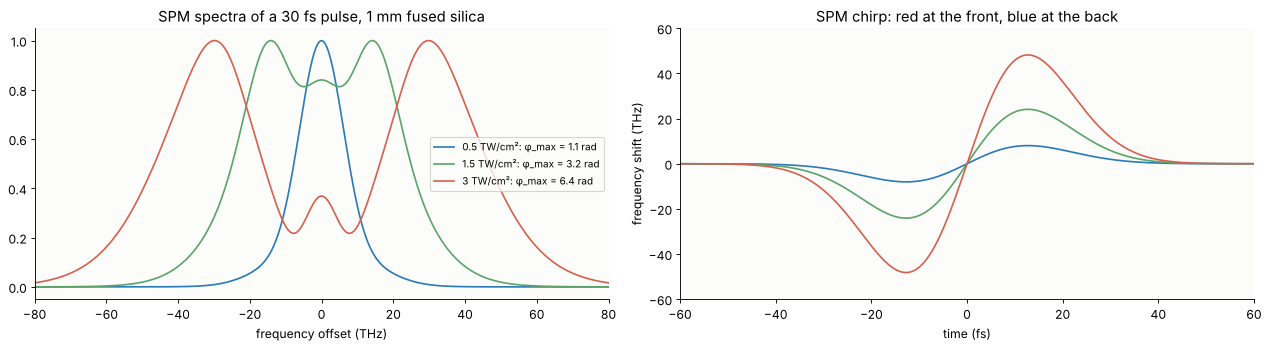

a 1 mm beam at 3 TW/cm² carries 47 GW = 19257 P_cr, collapse after 15 mm


In [6]:
# a 30 fs pulse at 800 nm through a 1 mm fused silica plate, on the axis of a wide beam
tt = np.linspace(-1000, 1000, 2**13, endpoint=False)          # fs
T0 = 30/1.665
gamma_I = 2*np.pi/lam*n2_fs*1E-3                               # per (W/m²) per mm: amplitudes in sqrt(W/m²)
beta2 = 36.0                                                   # fs²/mm, fused silica at 800 nm
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for I0, c in ((0.5E16, BLUE), (1.5E16, GREEN), (3.0E16, RED)):
    A0 = np.sqrt(I0)*np.exp(-tt**2/(2*T0**2))
    A = SS.nlse(tt, A0, 1.0, gamma=gamma_I, steps=400)
    phi = SS.spm_phase(I0, gamma_I, 1.0)
    Om, S = SS.spectrum(tt, A)
    f_thz = Om/(2*np.pi)*1E3
    axes[0].plot(f_thz, np.abs(S)**2/np.max(np.abs(S)**2), color=c, lw=1.5,
                 label=f"{I0/1E16:g} TW/cm²: φ_max = {phi:.1f} rad")
    Om0, S0p = SS.spectrum(tt, A0)
    rms = lambda w: np.sqrt(np.sum(Om**2*w)/np.sum(w))
    print("{:3.1f} TW/cm²: phi_max = {:4.1f} rad ({:3.1f} peaks expected), rms broadening {:4.2f} (formula {:4.2f})".format(
        I0/1E16, phi, phi/np.pi + 0.5, rms(np.abs(S)**2)/rms(np.abs(S0p)**2), SS.spm_broadening(phi)))
    inst = -np.gradient(np.unwrap(np.angle(A)), tt)/(2*np.pi)*1E3       # THz, pyoptics sign
    axes[1].plot(tt, inst, color=c, lw=1.5)
    A_d = SS.nlse(tt, A0, 1.0, betas=[beta2], gamma=gamma_I, steps=400)
    print("            with the dispersion of the plate: {:.1f} fs FWHM (input 30 fs), rms broadening {:4.2f}".format(
        fwhm(tt, np.abs(A_d)**2), rms(np.abs(SS.spectrum(tt, A_d)[1])**2)/rms(np.abs(S0p)**2)))
axes[0].set_xlim(-80, 80); axes[0].set_xlabel("frequency offset (THz)"); axes[0].legend(fontsize=9)
axes[0].set_title("SPM spectra of a 30 fs pulse, 1 mm fused silica")
axes[1].set_xlim(-60, 60); axes[1].set_ylim(-60, 60); axes[1].set_xlabel("time (fs)"); axes[1].set_ylabel("frequency shift (THz)")
axes[1].set_title("SPM chirp: red at the front, blue at the back")
plt.tight_layout()
plt.show()
w_plate = 1E-3
P_plate = 3.0E16*np.pi*w_plate**2/2
print("a 1 mm beam at 3 TW/cm² carries {:.0f} GW = {:.0f} P_cr, collapse after {:.0f} mm".format(
    P_plate/1E9, P_plate/P_cr, NL.self_focusing_distance(P_plate, P_cr, w_plate, lam, n0_fs)*1E3))

The rms broadening agrees with the formula to the last digit (1.37,
2.96 and 5.67 times), and the spectra show the expected number of peaks. The dispersion of 1 mm of
glass (36 fs²) already stretches the 30 fs pulse to 50 fs and reduces the
broadening. A wide beam carries 20 000 critical powers here and would
collapse after 15 mm, so the plate must be thin: a sequence of thin
plates, a hollow fibre filled with gas, or a solid fibre (notebook 121,
SPM and solitons in fibres) broadens spectra without collapse, and the
chirped broadened pulse is compressed afterwards to a few cycles.

## 6. Kerr-lens mode-locking

In a Ti:sapphire laser the crystal sits in the focus between two curved
mirrors. The Kerr lens of an intense pulse changes the resonator mode,
and an aperture (a slit, or the pump spot in the crystal) passes the
intense pulse with less loss than continuous light: an artificial fast
saturable absorber with the response time of the electronic Kerr effect.
`NL.kerr_lens_mode()` finds the self-consistent mode of a resonator with
a Kerr lens whose strength depends on the mode size in the crystal, by
iterating the ABCD eigenmode (`abcd.eigenmode()`, notebook 08, ABCD matrices). The resonator here has curved mirrors of 100 mm radius
separated by 103 mm, arms of 60 and 40 cm, a 3 mm crystal a little off
the centre, and a 0.6 mm aperture at the end mirror of the short arm.
`NL.kerr_lens_loss()` turns the transmission through the aperture into
the loss $q(P)$ per round trip.

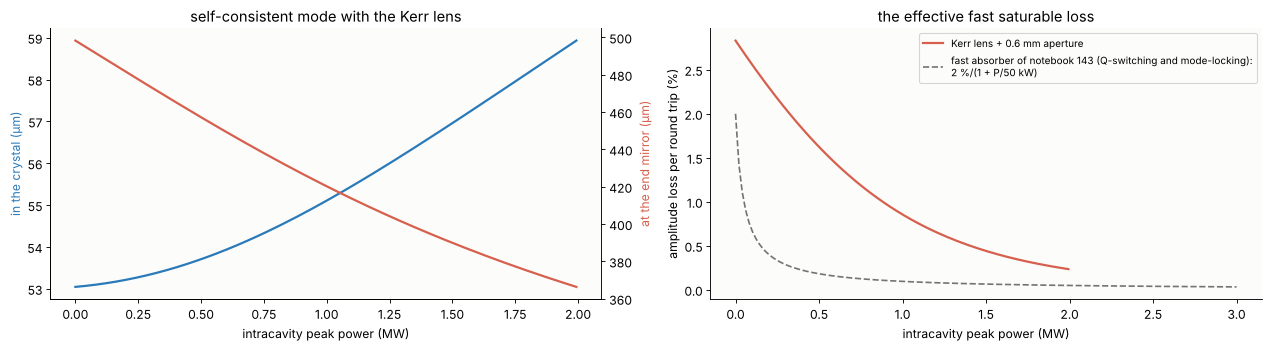

mode radius in the crystal 53.0 µm, at the aperture 498 µm (cw) and 420 µm at 1 MW
loss: 2.83 % cw, 1.62 % at 0.5 MW, 0.86 % at 1 MW


In [7]:
F, Lf = abcd.free_space, abcd.thin_lens
f_m, d1, d2, frac, delta = 0.05, 0.6, 0.4, 0.55, 3E-3      # curved mirrors f = R/2 = 50 mm, arms 60 and 40 cm
n2_ts, L_ts = NL.N2["sapphire"], 3E-3


def cavity(f_kerr, delta=delta):
    """round trip from the crystal (thin Kerr lens at each pass) and the path to the aperture at the end mirror"""
    K = Lf(f_kerr) if np.isfinite(f_kerr) else np.eye(2)
    zs = 2*f_m + delta
    z1, z2 = zs*frac, zs*(1 - frac)
    arm2 = abcd.compose(F(z2), Lf(f_m), F(d2), F(d2), Lf(f_m), F(z2))
    arm1 = abcd.compose(F(z1), Lf(f_m), F(d1), F(d1), Lf(f_m), F(z1))
    return abcd.compose(arm2, K, arm1, K), abcd.compose(F(z2), Lf(f_m), F(d2))


aperture = 0.6E-3
q_klm, table = NL.kerr_lens_loss(cavity, aperture, n2_ts, L_ts, lam, 3E6, n_powers=150)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ax = axes[0]
ax.plot(table["P"]/1E6, table["w_kerr"]*1E6, color=BLUE, lw=2, label="in the crystal")
ax2 = ax.twinx()
ax2.plot(table["P"]/1E6, table["w_aperture"]*1E6, color=RED, lw=2)
ax2.set_ylabel("at the end mirror (µm)", color=RED); ax2.spines["right"].set_visible(True)
ax.set_xlabel("intracavity peak power (MW)"); ax.set_ylabel("in the crystal (µm)", color=BLUE)
ax.set_title("self-consistent mode with the Kerr lens")
ax = axes[1]
ax.plot(table["P"]/1E6, table["loss"]*100, color=RED, lw=2, label="Kerr lens + 0.6 mm aperture")
ax.plot(table["P"]/1E6, 2.0/(1 + table["P"]/0.05E6), color=GREY, lw=1.5, ls="--",
        label="fast absorber of notebook 143 (Q-switching and mode-locking):\n2 %/(1 + P/50 kW)")
ax.set_xlabel("intracavity peak power (MW)"); ax.set_ylabel("amplitude loss per round trip (%)")
ax.set_title("the effective fast saturable loss"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("mode radius in the crystal {:.1f} µm, at the aperture {:.0f} µm (cw) and {:.0f} µm at 1 MW".format(
    table["w_kerr"][0]*1E6, table["w_aperture"][0]*1E6, np.interp(1E6, table["P"], table["w_aperture"])*1E6))
print("loss: {:.2f} % cw, {:.2f} % at 0.5 MW, {:.2f} % at 1 MW".format(q_klm(0)*100, q_klm(0.5E6)*100, q_klm(1E6)*100))

spm coefficient 0.160 per MW (mode radius 53.0 µm)


Kerr lens only           13.2 fs,  21.6 nJ, peak  1.25 MW, steady: True, soliton formula    nan fs


+ SPM, D = −25 fs²       29.7 fs,  18.9 nJ, peak  0.56 MW, steady: True, soliton formula   29.1 fs


+ SPM, D = −50 fs²       67.4 fs,  16.4 nJ, peak  0.21 MW, steady: True, soliton formula   67.4 fs


+ SPM, D = −100 fs²     143.6 fs,  15.3 nJ, peak  0.09 MW, steady: True, soliton formula  144.4 fs


+ SPM, no dispersion    454.2 fs,  14.4 nJ, peak  0.02 MW, steady: False, soliton formula    nan fs


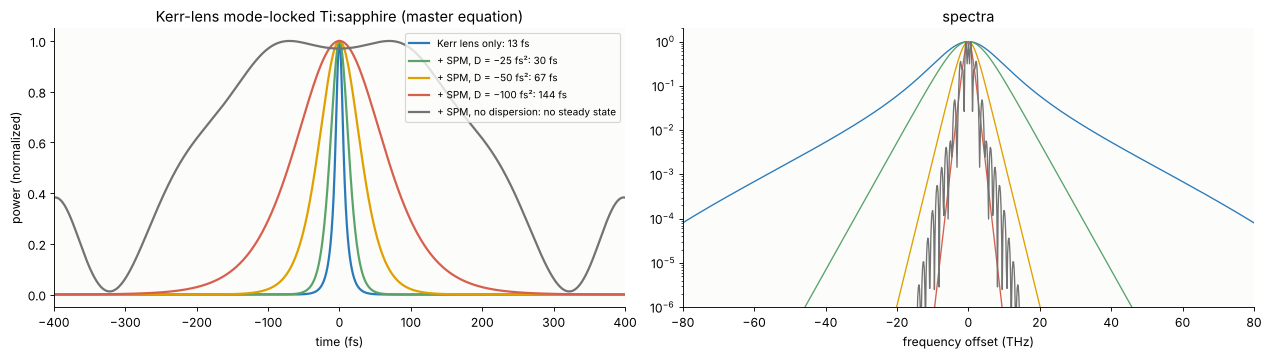

In [8]:
t_ml = np.linspace(-3000, 3000, 2**13, endpoint=False)    # fs; power in MW, energy in nJ
dt_ml = t_ml[1] - t_ml[0]
w_c = table["w_kerr"][0]
spm = 2*2*np.pi/lam*n2_ts*L_ts/(np.pi*w_c**2)*1E6       # two passes, per MW
q_sat = lambda P: q_klm(P*1E6) - q_klm(0.0)               # saturable part; the cw part is in the linear loss
A_start = (np.sqrt(0.05)/np.cosh(t_ml/300)).astype(complex)
cases = [("Kerr lens only", 0.0, 0.0, BLUE), ("+ SPM, D = −25 fs²", -25.0, spm, GREEN),
         ("+ SPM, D = −50 fs²", -50.0, spm, ORANGE), ("+ SPM, D = −100 fs²", -100.0, spm, RED),
         ("+ SPM, no dispersion", 0.0, spm, GREY)]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
print("spm coefficient {:.3f} per MW (mode radius {:.1f} µm)".format(spm, w_c*1E6))
for name, D, s, c in cases:
    A, h = LS.master_equation(t_ml, A_start, 8000, 0.1, 20.0, 0.05, 0.03 + q_klm(0.0), saturable_loss=q_sat,
                              gdd=D, spm=s, record_every=200)
    P = np.abs(A)**2
    E = P.sum()*dt_ml
    steady = abs(h["energy"][-1]/h["energy"][-5] - 1) < 1E-4
    width = fwhm(t_ml, P)
    sol = 1.763*2*abs(D)/(s*E) if (s and D) else np.nan
    print("{:22s} {:6.1f} fs, {:5.1f} nJ, peak {:5.2f} MW, steady: {}, soliton formula {:6.1f} fs".format(
        name, width, E, P.max(), steady, sol))
    axes[0].plot(t_ml, P/P.max(), color=c, lw=2, label=f"{name}: {width:.0f} fs" if steady else f"{name}: no steady state")
    f = np.fft.fftshift(np.fft.fftfreq(len(t_ml), dt_ml))*1E3
    Sp = np.abs(np.fft.fftshift(np.fft.ifft(A)))**2
    axes[1].semilogy(f, Sp/Sp.max(), color=c, lw=1.2)
axes[0].set_xlim(-400, 400); axes[0].set_xlabel("time (fs)"); axes[0].set_ylabel("power (normalized)")
axes[0].set_title("Kerr-lens mode-locked Ti:sapphire (master equation)"); axes[0].legend(fontsize=9)
axes[1].set_xlim(-80, 80); axes[1].set_ylim(1E-6, 2); axes[1].set_xlabel("frequency offset (THz)")
axes[1].set_title("spectra")
plt.tight_layout()
plt.show()

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 46 s


The mode at the aperture shrinks from 498 µm to 420 µm at 1 MW of
intracavity peak power, and the loss falls from 2.8 % to 0.9 %; the
resonator becomes unstable near 2 MW. Compared with the ideal fast
absorber of notebook 143 (Q-switching and mode-locking), the Kerr lens
saturates at much higher powers, near the critical power of sapphire
(1.8 MW), but it never stops saturating and has no recovery time.

Plugged into `lasers.master_equation()` as `saturable_loss` (the
saturable part of the loss; the continuous loss at zero power is added to
the linear loss), with a gain bandwidth of 50 THz and a saturation
energy of 20 nJ, the Kerr lens alone shortens the pulse to 13 fs at
1.25 MW, limited by the gain bandwidth. The self-phase modulation of the
same crystal (0.16 rad per MW per round trip for the 53 µm mode) without
dispersion destroys the steady state, as in notebook 143 (Q-switching and mode-locking): the pulse
breaks up. With negative group delay dispersion from prisms or chirped
mirrors the pulse becomes a soliton, sech² with the length
$1.763\cdot2|D|/(\delta E)$: 30, 67 and 144 fs for −25, −50 and −100 fs²,
within 2 % of the formula. Real Kerr-lens mode-locked lasers run near the
edge of a stability zone, where the mode reacts most strongly to the
Kerr lens, and often need a kick (a moved mirror) to start: the Kerr lens
is too weak for the noise of continuous operation, as the curve of the
loss at low power shows.

## Summary

- **Kerr effect** $n = n_0 + n_2I$, $n_2$ ≈ 3 × 10⁻²⁰ m²/W in glasses:
  1 rad per cm at 50 GW/cm².
- **Kerr lens** $f = \pi w^4/(8n_2LP)$, with spherical aberration.
- **Collapse** above $P_{cr} = 3.77\lambda^2/(8\pi n_0n_2)$ (2.5 MW in
  fused silica), at Marburger's distance; simulation within 5 to 12 %.
- **Small-scale self-focusing:** ripples near $K_m = \sqrt{2kk_0n_2I}$
  grow as $e^B$; amplifiers keep the B-integral below a few radians.
- **SPM:** spectral broadening $\sqrt{1 + 4\phi_{\max}^2/(3\sqrt3)}$,
  $\phi_{\max}/\pi + 1/2$ peaks, red front and blue back.
- **Kerr-lens mode-locking:** the Kerr lens and an aperture are a fast
  saturable loss for the master equation; with SPM and negative
  dispersion the pulse is a soliton.

## References

- R. W. Boyd, *Nonlinear Optics*, 4th ed., Academic Press (2020),
  chapters 4 and 7.
- J. H. Marburger, "Self-focusing: theory", Prog. Quantum Electron. 4,
  35–110 (1975).
- A. Couairon and A. Mysyrowicz, "Femtosecond filamentation in
  transparent media", Phys. Rep. 441, 47–189 (2007).
- V. I. Bespalov and V. I. Talanov, "Filamentary structure of light beams
  in nonlinear liquids", JETP Lett. 3, 307–310 (1966).
- W. Koechner, *Solid-State Laser Engineering*, 6th ed., Springer (2006),
  section 4.4 (B-integral).
- R. H. Stolen and C. Lin, "Self-phase-modulation in silica optical
  fibers", Phys. Rev. A 17, 1448–1453 (1978).
- D. E. Spence, P. N. Kean and W. Sibbett, "60-fsec pulse generation from
  a self-mode-locked Ti:sapphire laser", Opt. Lett. 16, 42–44 (1991).
- V. Magni, G. Cerullo and S. De Silvestri, "ABCD matrix analysis of
  propagation of Gaussian beams through Kerr media", Opt. Commun. 96,
  348–355 (1993).
- T. Brabec, C. Spielmann, P. F. Curley and F. Krausz, "Kerr lens mode
  locking", Opt. Lett. 17, 1292–1294 (1992).